# IND320 – Compulsory work, part 4

- GitHub: https://github.com/maryanahmed11011-pixel/IND320.prosjekt.maryan
- Streamlit app: https://ind320prosjektmaryan-lmvbjxajmrnrqkykq8ivne.streamlit.app/
- Screencast: *(link added when the video is ready)*

This notebook builds on parts 1–3. Part 4 adds exchange rates from Norges
Bank, a check of time zones across the data sources, forecasting of
reservoir filling with River, and a refactored Streamlit app with dynamic
Plotly plots, an interactive map and a new page structure.

## AI usage

*TODO: write a short description of how AI was used in part 4
(what it generated, what you wrote, tested and decided yourself).*

## Log

I started part 4 by following up the feedback on part 3. The weather page
now reads NVE's shapefiles from the repository instead of a map service.
Finding the layers in NVE Atlas took a while: the price areas are the layer
*Budområder*, and the precipitation areas are *NVE_Region*, which I
exported from each layer's table view. Two bugs showed up when the app ran
on Streamlit Cloud: Linux treats `nve_Region` and `nve_region` as different
folders, and the export has no `.cpg` file, so "RØ" was read wrongly and
VASS1 lost half its area. Both are fixed in `analysis.py`. I also put the
MongoDB upload behind a switch and made the app show an error message when
open-meteo rate-limits it.

Before changing the app, I sketched a structure based on task type
(Overview, Explore, Analyse, Predict). All matplotlib plots in the app
were replaced with Plotly, using a shared template in `theme.py`, and the
weather pages got a property selector with temperature as default.

The Norges Bank function was straightforward, and its output was a useful
check: the 11 weekdays without a rate in 2024 are the Norwegian public
holidays plus Christmas Eve. The time zone investigation was more
interesting than expected. Magasinstatistikk dates every week on its
Sunday, open-meteo applies a fixed UTC offset if a named time zone is
requested, and my ENTSO-E days from part 2 were UTC days, which explained
a strange year 2023 in the cross-border page. Three helper functions now
put all sources on local days and Sunday weeks.

The map was the hardest part. With a Plotly choropleth the clicks worked,
but the map disappeared for about a second on every click. By testing I
found that Streamlit rebuilds a Plotly chart whenever the figure changes,
so I switched to folium, where only the layer with the areas is replaced.
The sliding window correlation showed that temperature is most strongly
related to the weekly change in filling, especially during snowmelt, and
that precipitation matters most in the west (see section 6).

*TODO: forecasting with River (resolution, settings tested, best
default), the bonus task chosen, and the screencast.*

## 1. App structure (sketch)

Before changing the code, the pages were organised by **type of task**,
following the assignment's suggestion:

- **Overview:** the front page and the new interactive map, which is
  also where an area is selected.
- **Explore:** the data sources themselves – reservoir data (the
  `LineChartColumn` table and the plot page are merged into one data
  overview page), cross-border flows and exchange rates.
- **Analyse:** STL and spectrogram, weather anomalies (SATV/SPC and LOF)
  and the new sliding window correlation between weather and reservoirs.
- **Predict:** the new forecasting page.

The sidebar keeps two global selections in `st.session_state`: the
**area** (also set by clicking in the map) and the **time period**
(shared by the map and the forecast). Each menu group gets its own
colour, so it is clear which part of the app is active.



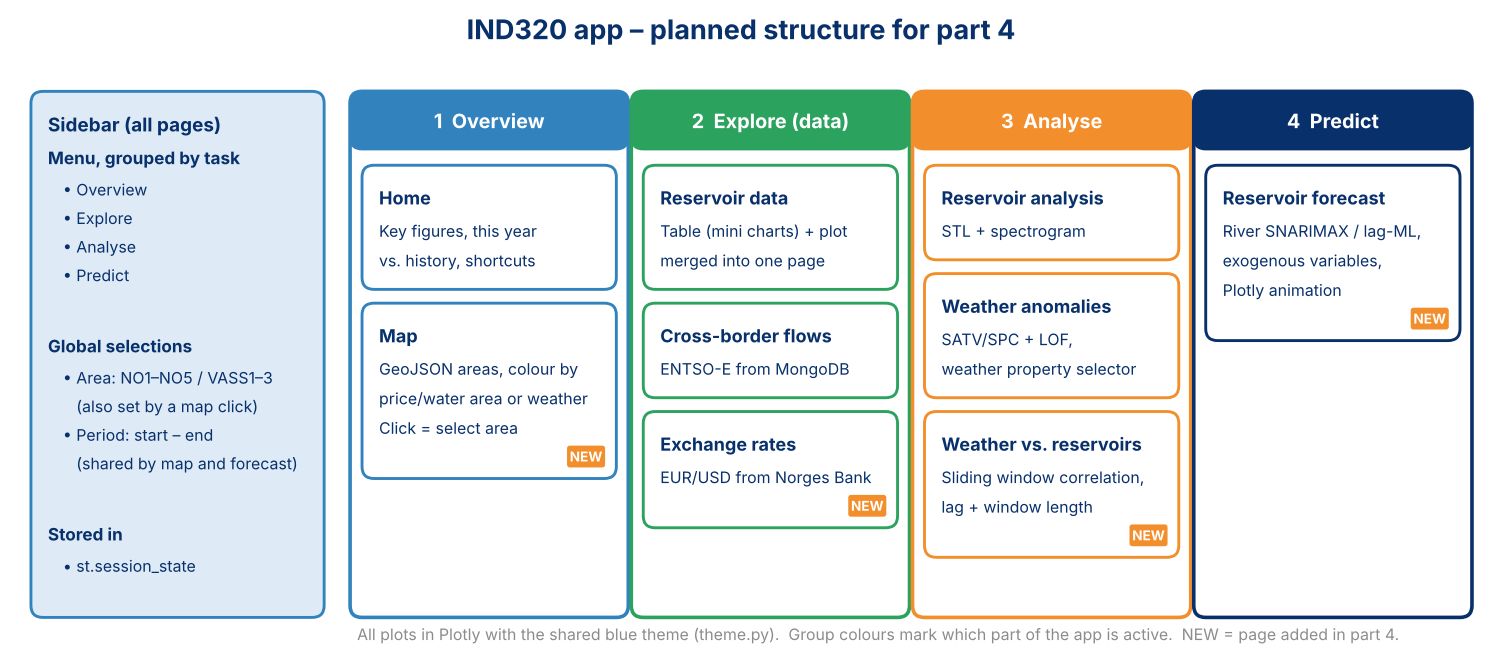

In [22]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("..")  # the notebook is in notebooks/, the app code in the root

import theme  # noqa: F401  shared colours (also the matplotlib style)
from analysis import fetch_exchange_rates
from theme import COLORS

# The sketch is shown as cell output, so it is embedded in the HTML/PDF export
from IPython.display import Image
Image("figures/app_structure.png")

## 2. Exchange rates from Norges Bank

Norges Bank has an open SDMX API with no key. A series is identified by
a key such as `B.EUR+USD.NOK.SP`: business-day frequency (`B`), the
base currencies EUR and USD (`+` fetches several in one call), quoted in
NOK, spot rates (`SP`). The function `fetch_exchange_rates` in
`analysis.py` asks for CSV, picks the date, currency and value columns,
corrects for currencies quoted per 100 units, and returns one column per
currency in NOK per unit. The same function will be used in the app.

In [2]:
# EUR and USD for 2024 (the same year as the weather data for NO3)
rates = fetch_exchange_rates(("EUR", "USD"), start="2024-01-01",
                             end="2024-12-31")
print(rates.shape[0], "business days")
rates.head()

251 business days


,EUR,USD
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


In [3]:
# Quick check: summary per currency and the number of missing days
print(rates.describe().round(3))
print("Missing values:", rates.isna().sum().to_dict())

           EUR      USD
count  251.000  251.000
mean    11.628   10.743
std      0.192    0.244
min     11.268   10.297
25%     11.448   10.546
50%     11.668   10.694
75%     11.771   10.950
max     12.111   11.423
Missing values: {'EUR': 0, 'USD': 0}


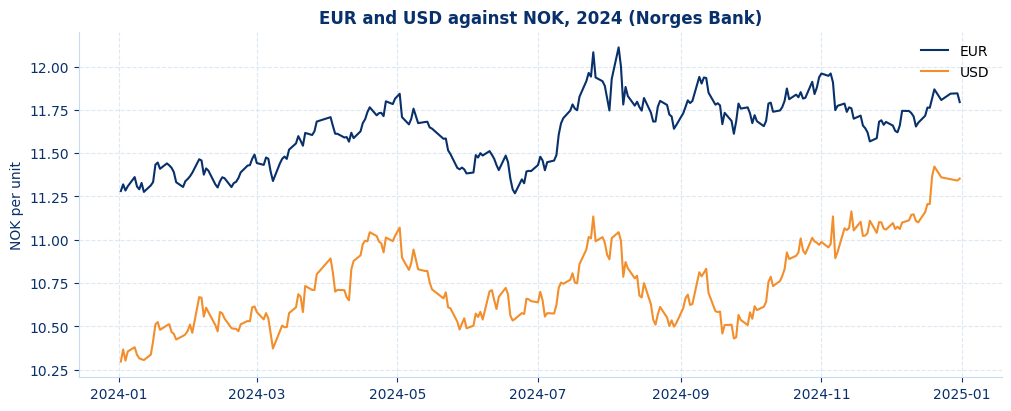

In [4]:
# Both rates over 2024. Weekends and Norwegian holidays have no rate,
# so the lines only have points on business days.
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.plot(rates.index, rates["EUR"], color=COLORS["dark"], label="EUR")
ax.plot(rates.index, rates["USD"], color=COLORS["accent"], label="USD")
ax.set(ylabel="NOK per unit", title="EUR and USD against NOK, 2024 "
       "(Norges Bank)")
ax.legend()
plt.show()

Both rates move largely together, since much of the variation comes from
the krone itself: when NOK weakens, both EUR and USD become more
expensive. In 2024 one euro cost between 11.27 and 12.11 NOK (mean
11.63) and one dollar between 10.30 and 11.42 NOK (mean 10.74). Both
rates rose in spring, fell back in June and had a short peak in early
August. Towards the end of the year the two rates drift apart: the euro
stays around 11.7–11.8 NOK, while the dollar rises clearly and ends the
year near its maximum. The dollar is also slightly more volatile
(standard deviation 0.24 vs. 0.19 NOK). The data are business days only
(251 days, no missing values), so weekends and holidays must be filled
or skipped before the rates are combined with daily or hourly data.

## 3. Time zones in the data sources

The four sources are combined later (correlation, forecasting), so their
time stamps must mean the same thing. Norway uses CET (UTC+1) in winter
and CEST (UTC+2) in summer, so a naive mix of UTC and local time shifts
data by one or two hours, and can move values across a day or week
boundary. Each source is checked below.

### 3.1 Magasinstatistikk (NVE)

Weekly values with a date (`dato_Id`), ISO year and ISO week, but no time
of day or time zone. The check below shows which weekday the date falls
on, and whether it belongs to the ISO week given in the data.

In [5]:
import numpy as np
import requests

from analysis import (ERA5_URL, LOCAL_TZ, daily_to_weekly, download_era5,
                      hourly_to_daily, utc_to_local)

RES_URL = ("https://biapi.nve.no/magasinstatistikk/api/"
           "Magasinstatistikk/HentOffentligData")
res = pd.DataFrame(requests.get(RES_URL, timeout=30).json())
res["dato_Id"] = pd.to_datetime(res["dato_Id"])

# Which weekday is the date, and does it match the ISO week in the data?
iso = res["dato_Id"].dt.isocalendar()
print("Weekdays of dato_Id:", res["dato_Id"].dt.day_name().value_counts().to_dict())
print("Date matches iso_aar/iso_uke:",
      ((iso["year"] == res["iso_aar"]) & (iso["week"] == res["iso_uke"])).mean())

# Publication time of the next update (no time zone given)
pub = pd.to_datetime(res["neste_Publiseringsdato"], errors="coerce")
pub = pub[pub.dt.year > 2000]  # 0001-01-01 is used for "no date"
print("Next publication:", pub.max(), "-", pub.max().day_name())

Weekdays of dato_Id: {'Sunday': 14967}
Date matches iso_aar/iso_uke: 1.0
Next publication: 2026-11-25 13:00:00 - Wednesday


All 14 967 dates are Sundays, and every date lies in the ISO week given
by `iso_aar` and `iso_uke`. A weekly value therefore describes the week
Monday–Sunday and is dated on its last day. The next publication is
given as a local Norwegian time without offset (Wednesday 13:00), so new
data for a week arrives three days after the week has ended. This lag
matters for forecasting: the newest known week is always the previous
one.

### 3.2 ERA5 from open-meteo

The weather data is downloaded with `timezone=GMT`, so the hourly time
stamps are UTC. According to the open-meteo documentation, a named time
zone is applied as **one fixed UTC offset**, resolved at request time.
Asking for `Europe/Oslo` would therefore not follow the switch to and
from summer time, which is why the project asks for UTC and converts
afterwards. The cells below download two days around each switch for
one point (Trondheim) and compare the two options.

In [6]:
# One point, three days around each summer-time switch in 2024.
# The switch day is in the middle: the first and last local day are
# partial, because a UTC download starts 1-2 hours before local midnight.
point = pd.DataFrame({"lat": [63.43], "lon": [10.39]})
spring = download_era5(point, "2024-03-30", "2024-04-01").set_index("time")
autumn = download_era5(point, "2024-10-26", "2024-10-28").set_index("time")

# UTC: always 24 hours per day
print("Hours per UTC day (spring):",
      spring.groupby(spring.index.date).size().tolist())

# Converted to local time: the switch days get 23 and 25 hours
for name, df, day in [("spring", spring, "2024-03-31"),
                      ("autumn", autumn, "2024-10-27")]:
    local = utc_to_local(df[["temperature_2m"]])
    n = local.loc[day].shape[0]
    print(f"Hours on the local switch day {day} ({name}): {n}")

Hours per UTC day (spring): [24, 24, 24]
Hours on the local switch day 2024-03-31 (spring): 23
Hours on the local switch day 2024-10-27 (autumn): 25


In [7]:
# The same request with timezone=Europe/Oslo: which offset is used?
params = {"latitude": 63.43, "longitude": 10.39, "start_date": "2024-03-30",
          "end_date": "2024-03-31", "hourly": "temperature_2m",
          "models": "era5", "timezone": LOCAL_TZ}
oslo = requests.get(ERA5_URL, params=params, timeout=60).json()
print("utc_offset_seconds:", oslo["utc_offset_seconds"],
      "| first and last time stamp:", oslo["hourly"]["time"][0],
      oslo["hourly"]["time"][-1], "| hours:", len(oslo["hourly"]["time"]))

utc_offset_seconds: 3600 | first and last time stamp: 2024-03-30T00:00 2024-03-31T23:00 | hours: 48


The request with `timezone=Europe/Oslo` returned one fixed offset of
3600 s (UTC+1) and 48 time stamps from 00:00 to 23:00 on both days. The
switch to summer time at 02:00 on 31 March is ignored, so every local
time after the switch is one hour wrong. The offset also depends on when
the request is made: run in summer, the same request would use UTC+2 for
the whole period. Requesting UTC and converting with `utc_to_local`
avoids both problems and gives 23 and 25 hours on the switch days.

Precipitation in ERA5 from open-meteo is the sum over the **preceding**
hour, so the value stamped 00:00 belongs to the day before. Converting
to local time shifts this boundary by one or two hours, which is small
compared to daily and weekly sums.

### 3.3 ENTSO-E (cross-border flows, part 2)

In part 2 the hourly flows were queried with start and end in
Europe/Oslo time, converted to **UTC**, and aggregated to days with
Spark (`F.to_date("time")` with the Spark session in UTC). A "day" in
MongoDB is therefore a UTC day, which is 01:00–01:00 local time in
winter and 02:00–02:00 in summer. The pure pandas example below shows
what this does at the start and end of the downloaded period.

In [8]:
# Hours of the downloaded period (local time), as stored (UTC)
hours = pd.date_range("2024-01-01", "2026-01-01", freq="h",
                      tz=LOCAL_TZ, inclusive="left").tz_convert("UTC")
per_utc_day = pd.Series(1, index=hours).groupby(hours.date).sum()
print("First UTC days:", per_utc_day.head(2).to_dict())
print("Last UTC day:", per_utc_day.tail(1).to_dict())

First UTC days: {datetime.date(2023, 12, 31): 1, datetime.date(2024, 1, 1): 24}
Last UTC day: {datetime.date(2025, 12, 31): 23}


The output confirms this: the first hour of 2024 (00:00–01:00 local) ends up as a one-hour
"day" on 31 December 2023, and the last UTC day of 2025 has only 23
hours. In the app, this showed up as an extra year 2023 with almost no
energy in the year selector on the cross-border page. `load_flows` in
`utils.py` now leaves out days before 1 January 2024.

**Solution:** aggregate on local days instead, i.e. in Spark
`F.to_date(F.from_utc_timestamp("time", "Europe/Oslo"))`, or with
`hourly_to_daily` in pandas. The daily data is only used for overviews
in this project, so the one-to-two-hour shift does not change any
conclusions, but it matters if flows are later compared day by day with
weather or prices.

### 3.4 Norges Bank (exchange rates)

The API returns one value per **Norwegian business day**, as a date
without time. According to Norges Bank, the rates are a snapshot taken
at 14:15 CET and published around 16:00 CET. Weekends and Norwegian
public holidays have no rate.

In [9]:
# Weekdays in the exchange rates from section 2
print("Weekdays:", rates.index.day_name().value_counts().to_dict())

# Weekdays in 2024 without a rate = Norwegian public holidays
weekdays = pd.bdate_range("2024-01-01", "2024-12-31")
print("Weekdays without a rate:",
      [d.strftime("%a %d %b") for d in weekdays.difference(rates.index)])

Weekdays: {'Tuesday': 52, 'Wednesday': 50, 'Friday': 50, 'Monday': 50, 'Thursday': 49}
Weekdays without a rate: ['Mon 01 Jan', 'Thu 28 Mar', 'Fri 29 Mar', 'Mon 01 Apr', 'Wed 01 May', 'Thu 09 May', 'Fri 17 May', 'Mon 20 May', 'Tue 24 Dec', 'Wed 25 Dec', 'Thu 26 Dec']


There are rates only on Monday–Friday (251 days in 2024). Of the 262
weekdays in 2024, 11 have no rate: the ten Norwegian public holidays
that fell on a weekday (1 January, Maundy Thursday, Good Friday, Easter
Monday, 1 May, Ascension Day, 17 May, Whit Monday, 25 and 26 December)
and Christmas Eve, when Norges Bank does not publish rates. The rates
follow the Norwegian calendar, not UTC, and need no time zone
conversion. When combined with daily data, missing days must be skipped
or filled (e.g. with the previous business day's rate); for weekly means
they are simply left out.

### 3.5 Summary and solution

| Source | Resolution | Time stamp | Time zone |
|---|---|---|---|
| Magasinstatistikk | weekly | Sunday ending the ISO week | none (Norwegian calendar) |
| ERA5 / open-meteo | hourly | start of hour (precipitation: sum of preceding hour) | UTC (requested with GMT) |
| ENTSO-E (MongoDB) | daily (from hourly) | UTC day | UTC |
| Norges Bank | business days | date, snapshot 14:15 CET | Norwegian calendar |

**Common reference:** local Norwegian calendar days, and ISO weeks ending
on Sunday, labelled with the Sunday's date like Magasinstatistikk.
Three helper functions in `analysis.py` do the conversion, and they will
be used in the correlation and forecasting parts:

- `utc_to_local`: naive UTC → Europe/Oslo (handles summer time).
- `hourly_to_daily`: hourly UTC → local days (precipitation summed,
  other variables averaged); drops partial days at the edges.
- `daily_to_weekly`: days or business days → weeks ending on Sunday.

In [10]:
# Example: NO3 weather (section 2 has 2024 for one point; here the same
# point for the whole year) and exchange rates on the reservoir week grid
weather = download_era5(point, "2024-01-01", "2024-12-31").set_index("time")
weather = weather.drop(columns="location_id")
weekly_weather = daily_to_weekly(hourly_to_daily(weather))
weekly_rates = daily_to_weekly(rates)

filling_no3 = (res[(res["omrType"] == "EL") & (res["omrnr"] == 3)]
               .set_index("dato_Id")["fyllingsgrad"].sort_index())

combined = (weekly_weather.join(weekly_rates)
            .join(filling_no3.rename("filling_degree"), how="inner"))
print(combined.shape)
combined.head()

(53, 7)


,temperature_2m,precipitation,wind_speed_10m,relative_humidity_2m,EUR,USD,filling_degree
2024-01-07,-7.920549,0.9,12.803442,64.725932,11.29875,10.330575,0.497182
2024-01-14,3.785119,52.1,13.447619,91.238095,11.31326,10.329660,0.476007
2024-01-21,-8.844048,3.6,6.263690,81.000000,11.38740,10.453820,0.441178
2024-01-28,4.153571,37.3,11.378571,80.982143,11.40186,10.473680,0.428328
2024-02-04,2.867262,51.2,17.220238,75.029762,11.34956,10.469500,0.423203


All sources now share the same weekly index (Sundays), so they can be
joined without shifting any values: weather as weekly means
(precipitation as weekly sums, e.g. 52 mm in the week ending 14 January),
the exchange rates as weekly means of the business days, and the filling
degree as published. Note that the weather here is for one point only;
in the correlation and forecasting parts the regional averages over the
sampled points are used instead.

## 4. Map areas as GeoJSON

The interactive map in the app needs the areas as GeoJSON. The NVE
shapefiles from part 3 (`geo/budomrader` and `geo/nve_region`) are read
with the same `load_areas` function as before, merged per area
(RØ + RS → VASS1, RM + RN → VASS3), simplified and written to two
GeoJSON files in `geo/`:

- `price_areas.geojson`: NO1–NO5
- `water_areas.geojson`: VASS1–VASS3

Simplifying with a tolerance of 0.01° (about 1 km) removes small details
along the coast that are invisible at country scale, and makes the files
much smaller, so the map loads quickly. Each area also gets a point
inside it (`lon`, `lat`), used for the clickable labels on the map.

In [11]:
import json

from analysis import area_geojson, load_areas, save_area_geojson

GEO_DIR = Path("../geo")

# Size of the shapefiles compared with the simplified GeoJSON files
shp_kb = sum(f.stat().st_size for f in GEO_DIR.rglob("*.shp")) / 1024
paths = save_area_geojson(GEO_DIR)
for path in paths:
    gj = json.loads(path.read_text(encoding="utf-8"))
    print(f"{path.name}: {path.stat().st_size / 1024:.0f} kB,",
          [f["properties"]["region"] for f in gj["features"]])
print(f"Shapefiles (.shp only): {shp_kb:.0f} kB")

price_areas.geojson: 38 kB, ['NO1', 'NO2', 'NO3', 'NO4', 'NO5']
water_areas.geojson: 61 kB, ['VASS1', 'VASS2', 'VASS3']
Shapefiles (.shp only): 1375 kB


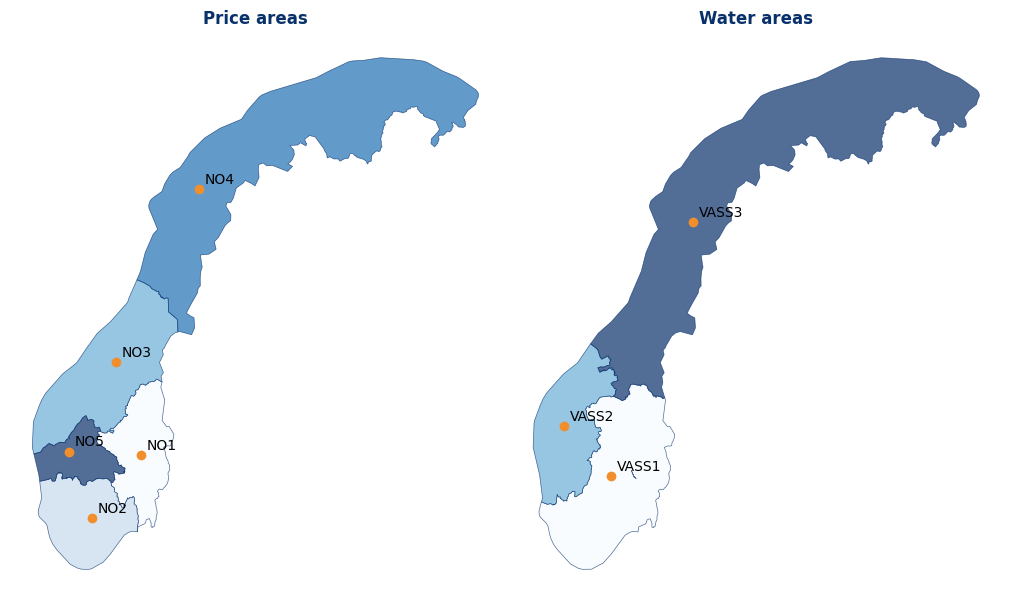

In [12]:
# Quick look at the converted outlines and the label points
import geopandas as gpd

fig, axes = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
for ax, path in zip(axes, paths):
    gdf = gpd.read_file(path)
    gdf.plot(ax=ax, column="region", cmap="Blues", edgecolor=COLORS["dark"],
             linewidth=0.5, alpha=0.7)
    ax.scatter(gdf["lon"], gdf["lat"], color=COLORS["accent"], zorder=3)
    for _, row in gdf.iterrows():
        ax.annotate(row["region"], (row["lon"], row["lat"]),
                    xytext=(4, 4), textcoords="offset points")
    ax.set_title(path.stem.replace("_", " ").capitalize())
    ax.set_axis_off()
plt.show()

*TODO: comment on the result (file sizes before and after, and whether
the outlines and label points look right).*

## 5. Forecasting reservoir filling with River

**Model.** River's `time_series.SNARIMAX` (seasonal non-linear ARIMA with
exogenous variables) learns one week at a time with `learn_one` and
forecasts recursively, so every step of the forecast builds on the
previous forecast steps (dynamic forecasting). The function
`forecast_filling` in `analysis.py` takes the model parameters, the
length of the history, the horizon and the exogenous data sources as
inputs, and is used both here and in the app.

**Time resolution.** Weekly, which is the resolution of
Magasinstatistikk. A finer resolution would only interpolate the target,
and the weather and exchange rates are put on the same Sunday weeks with
the helpers from section 3. Weekly data also keeps the training fast:
about 520 `learn_one` calls for ten years of history.

**Exogenous variables.** Weather (temperature and precipitation, from
the findings in section 6) and the EUR exchange rate. Their future
values are unknown when forecasting, so by default the weekly averages
over the training period are used (*climatology*). Using the *observed*
future values is only possible when testing on the past, and shows how
much better the forecast could be with a perfect weather forecast.

**Testing.** Each setting is tested from 26 start weeks (every four
weeks through 2023–2024): the model learns the history up to the start
week and forecasts the next 12 weeks. The error is the mean absolute
error (MAE, percentage points of filling). Every setting is compared
with a simple baseline: the newest level plus last year's change over the
same weeks (`seasonal_naive`).

In [13]:
import time

from analysis import (FORECAST_DEFAULTS, HOURLY_VARS, backtest_forecast,
                      fetch_exchange_rates, forecast_filling, sample_locations,
                      seasonal_naive)

# Target: weekly filling degree for NO3 (%), all weeks since 1995
y_no3 = filling_no3 * 100

# Exogenous data, 2015-2025: weather for NO3 (5 random points, as in the
# app) and the EUR rate, on the same Sunday weeks (section 3)
locs = sample_locations(load_areas(GEO_DIR), n=1000, seed=42)
no3_points = locs[locs["region"] == "NO3"]
hourly_no3 = (download_era5(no3_points, "2015-01-01", "2025-12-31", max_points=5)
              .groupby("time")[HOURLY_VARS].mean())
weekly_no3_all = daily_to_weekly(hourly_to_daily(hourly_no3))
eur_weekly = daily_to_weekly(fetch_exchange_rates(("EUR",), start="2015-01-01",
                                                  end="2025-12-31"))
X_no3 = weekly_no3_all.join(eur_weekly)
print(y_no3.shape, X_no3.shape)
X_no3.tail(3)

(1663,) (575, 5)


,temperature_2m,precipitation,wind_speed_10m,relative_humidity_2m,EUR
time,,,,,
2025-12-21,5.711905,34.78,23.800238,83.022619,11.94956
2025-12-28,4.870714,27.86,29.773810,81.260714,11.86825
2026-01-04,0.591667,24.66,27.738889,81.247222,11.83200


In [14]:
# One forecast with the default settings, and how long it takes
t0 = time.perf_counter()
fc = forecast_filling(y_no3, end="2024-06-02", **FORECAST_DEFAULTS)
print(f"Training on {FORECAST_DEFAULTS['history_weeks']} weeks + forecast: "
      f"{time.perf_counter() - t0:.2f} s")
pd.DataFrame({"forecast": fc, "actual": y_no3.reindex(fc.index),
              "baseline": seasonal_naive(y_no3, "2024-06-02", 12)}).round(1)

Training on 520 weeks + forecast: 0.28 s


,forecast,actual,baseline
2024-06-09,62.2,60.0,62.5
2024-06-16,71.9,63.5,71.4
2024-06-23,79.3,66.0,78.4
2024-06-30,84.2,68.7,82.7
2024-07-07,86.2,70.6,84.2
2024-07-14,90.5,72.8,88.0
2024-07-21,93.0,73.5,89.9
2024-07-28,93.7,75.2,90.1
2024-08-04,94.5,75.2,90.4
2024-08-11,100.0,77.2,96.2


### 5.1 Testing settings

The settings are tested in three steps, so the number of runs stays
small: first the ARIMA orders without exogenous variables, then the
exogenous variables and the length of history for the best orders, and
finally how the error grows with the horizon.

In [15]:
# Start weeks for the tests: every four weeks through 2023-2024
origins = pd.date_range("2023-01-01", "2024-12-29", freq="4W-SUN")

def score(**settings):
    """Mean MAE over all start weeks for one setting."""
    bt = backtest_forecast(y_no3, origins, X=X_no3, **settings)
    return pd.Series({"MAE": bt["mae"].mean(),
                      "MAE baseline": bt["mae_baseline"].mean(),
                      "seconds per run": bt["seconds"].mean()})

# Step 1: ARIMA orders (no exogenous variables, 10 years of history)
orders = {
    "p=1, d=1": dict(p=1, d=1, q=0),
    "p=2, d=1": dict(p=2, d=1, q=0),
    "p=4, d=1": dict(p=4, d=1, q=0),
    "p=2, d=1, q=1": dict(p=2, d=1, q=1),
    "p=2, d=1, sp=1": dict(p=2, d=1, q=0, sp=1),
    "p=2, d=1, sd=1": dict(p=2, d=1, q=0, sd=1),
    "p=2, d=0, sd=1": dict(p=2, d=0, q=0, sd=1),
}
step1 = pd.DataFrame({name: score(history_weeks=520, horizon=12, m=52, **o)
                      for name, o in orders.items()}).T
step1.sort_values("MAE").round(2)

,MAE,MAE baseline,seconds per run
"p=2, d=0, sd=1",6.26,6.11,0.02
"p=2, d=1, sd=1",6.34,6.11,0.02
"p=2, d=1, sp=1",7.33,6.11,0.02
"p=2, d=1, q=1",11.27,6.11,0.03
"p=1, d=1",11.31,6.11,0.02
"p=2, d=1",11.40,6.11,0.02
"p=4, d=1",11.75,6.11,0.02


In [16]:
# Step 2: exogenous variables and length of history, with the best orders
best_order = orders[step1["MAE"].idxmin()]
print("Best orders:", best_order)

exog_sets = {
    "none": [],
    "temperature": ["temperature_2m"],
    "temperature + precipitation": ["temperature_2m", "precipitation"],
    "temperature + precipitation + EUR": ["temperature_2m", "precipitation", "EUR"],
}
rows = {}
for name, exog in exog_sets.items():
    for weeks in (260, 520):
        rows[(name, weeks, "climatology")] = score(
            exog=exog, history_weeks=weeks, horizon=12, m=52, **best_order)
    if exog:  # upper bound: if the future weather had been known
        rows[(name, 520, "observed")] = score(
            exog=exog, history_weeks=520, horizon=12, m=52,
            future="observed", **best_order)
step2 = pd.DataFrame(rows).T
step2.index.names = ["exogenous", "history (weeks)", "future exogenous"]
step2.sort_values("MAE").round(2)

Best orders: {'p': 2, 'd': 0, 'q': 0, 'sd': 1}


MAE  \
exogenous                         history (weeks) future exogenous         
temperature + precipitation       520             observed          6.25   
none                              520             climatology       6.26   
temperature + precipitation       520             climatology       6.41   
temperature                       520             climatology       6.75   
                                                  observed          6.81   
temperature + precipitation       260             climatology       7.75   
temperature + precipitation + EUR 520             observed          7.90   
temperature                       260             climatology       8.06   
none                              260             climatology       8.07   
temperature + precipitation + EUR 260             climatology       8.70   
                                  520             climatology       9.99   

                                                                    MAE baseline  \
exogenous                         history (weeks) future exogenous                 
temperature + precipitation       520             observed                  6.11   
none                              520             climatology               6.11   
temperature + precipitation       520             climatology               6.11   
temperature                       520             climatology               6.11   
                                                  observed                  6.11   
temperature + precipitation       260             climatology               6.11   
temperature + precipitation + EUR 520             observed                  6.11   
temperature                       260             climatology               6.11   
none                              260             climatology               6.11   
temperature + precipitation + EUR 260             climatology               6.11   
                                  520             climatology               6.11   

                                                                    seconds per run  
exogenous                         history (weeks) future exogenous                   
temperature + precipitation       520             observed                     0.05  
none                              520             climatology                  0.02  
temperature + precipitation       520             climatology                  0.05  
temperature                       520             climatology                  0.06  
                                                  observed                     0.05  
temperature + precipitation       260             climatology                  0.03  
temperature + precipitation + EUR 520             observed                     0.06  
temperature                       260             climatology                  0.03  
none                              260             climatology                  0.01  
temperature + precipitation + EUR 260             climatology                  0.03  
                                  520             climatology                  0.06

In [17]:
# Step 3: error by horizon for the best setting (climatology only, since
# the future weather is not known when forecasting)
realistic = step2.xs("climatology", level="future exogenous")
best_exog_name, best_weeks = realistic["MAE"].idxmin()
best = dict(exog=exog_sets[best_exog_name], history_weeks=int(best_weeks),
            m=52, **best_order)
print("Best setting:", best)

step3 = pd.DataFrame({h: score(horizon=h, **best) for h in (4, 8, 12, 26)}).T
step3.index.name = "horizon (weeks)"
step3.round(2)

Best setting: {'exog': [], 'history_weeks': 520, 'm': 52, 'p': 2, 'd': 0, 'q': 0, 'sd': 1}


,MAE,MAE baseline,seconds per run
horizon (weeks),,,
4,3.35,3.40,0.02
8,5.05,4.99,0.02
12,6.26,6.11,0.02
26,8.83,8.39,0.02


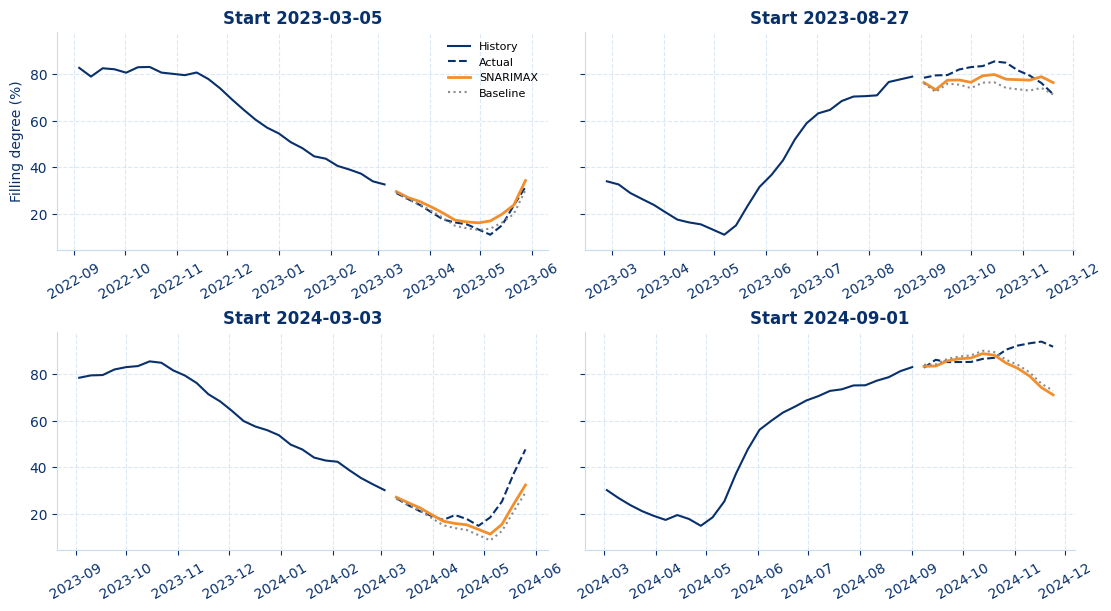

In [18]:
# Forecasts from four start weeks with the best setting, against the actual
# filling and the baseline
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True, layout="constrained")
for ax, start in zip(axes.flat, ["2023-03-05", "2023-08-27", "2024-03-03",
                                 "2024-09-01"]):
    fc = forecast_filling(y_no3, X=X_no3, end=start, horizon=12, **best)
    past = y_no3[pd.Timestamp(start) - pd.Timedelta(weeks=26):start]
    ax.plot(past.index, past, color=COLORS["dark"], label="History")
    ax.plot(fc.index, y_no3.reindex(fc.index), color=COLORS["dark"], ls="--",
            label="Actual")
    ax.plot(fc.index, fc, color=COLORS["accent"], lw=2, label="SNARIMAX")
    ax.plot(fc.index, seasonal_naive(y_no3, start, 12), color=COLORS["neutral"],
            ls=":", label="Baseline")
    ax.set_title(f"Start {start}")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].set_ylabel("Filling degree (%)")
axes[0, 0].legend(fontsize=8)
plt.show()

### 5.2 Findings

**ARIMA orders.** Without seasonal terms the model does badly: with
p = 1–4 and d = 1 the mean error over 12 weeks is about 11–12 percentage
points, almost twice the baseline (6.1). The model only continues the
recent trend, so a forecast started in early summer keeps rising and can
pass 100 % (this is why the forecasts are now clipped to 0–100 %).
Seasonal differencing (`sd=1`, m = 52) is what makes the difference: it
brings the error down to 6.3, about the same as the baseline, because
the model then forecasts the change relative to the same week last
year. A seasonal AR term (`sp=1`) instead of differencing gives 7.3.

**Exogenous variables.** None of them improved the forecast. With
temperature and precipitation, and their weekly averages as future values
(climatology), the error was 6.4, slightly worse than without (6.3).
Even with the *observed* future weather, which is not available in a
real forecast, the error was 6.25, practically the same. Adding the EUR
rate made the forecast clearly worse (7.9–10.0), which makes sense: the
exchange rate has no direct effect on the inflow. The weather is already
"in" the seasonal pattern, and in a linear model the week-to-week weather
explains too little of the deviation from last year to help. Ten years of
history was better than five in every case (e.g. 6.3 vs. 8.1 without
exogenous variables).

**Horizon.** The error grows from 3.4 percentage points after 4 weeks to
5.1 after 8, 6.3 after 12 and 8.8 after 26 weeks. The model is marginally
better than the baseline at 4 weeks and slightly worse at 26 weeks. The
plots show where it struggles: the timing of the snowmelt. In spring 2024
the filling rose earlier and faster than both the model and the baseline
expected.

**Time and resolution.** One training run on ten years of weekly data
plus a forecast takes about 0.02 s in the tests, so weekly resolution is
more than fast enough for the app; daily data would give seven times as
many steps without more information in the target.

**Default in the app.** `p=2, d=0, q=0, sd=1, m=52`, ten years of history
and no exogenous variables (`FORECAST_DEFAULTS` in `analysis.py`). The
exogenous variables can still be chosen in the app, so their effect can
be tried for other areas, where e.g. precipitation matters more (VASS2,
section 6).

## 6. Sliding window correlation: weather vs. reservoirs

The lecture's `lagged_correlation_plot` (ipywidgets + matplotlib) is
turned into the Streamlit page **Weather vs. Reservoirs** with Plotly.
The calculations are in `analysis.py`, so the notebook and the app use
the same code:

- `lagged_correlation(y, x, lag)`: correlation between y(t) and
  x(t − lag) over the whole period, i.e. the weather `lag` weeks earlier.
- `correlation_by_lag(y, x, max_lag)`: the same for every lag.
- `sliding_window_correlation(y, x, window, lag)`: centred rolling
  correlation, which shows how the relationship changes over time.

Both series use the weekly grid from section 3 (weeks ending on Sunday,
local time). As the representative variable from Magasinstatistikk, the
**weekly change** in filling degree is used by default rather than the
level: the level and most weather properties both follow the seasons, so
they correlate strongly even without a direct link. The example below
uses NO3 for 2019–2025 with five random points (the same as the app).

In [19]:
from analysis import correlation_by_lag, sliding_window_correlation

# NO3 weather and filling from section 5, here for 2019-2025
weekly_no3 = weekly_no3_all.loc["2019":"2025"]
fill_no3 = y_no3
change_no3 = fill_no3.diff().rename("change")
print(weekly_no3.shape, change_no3.dropna().shape)

(365, 4) (1662,)


                  0     1     2     3     4     5     6     7     8     9   \
temperature_2m  0.62  0.52  0.42  0.36  0.31  0.24  0.17  0.10  0.03 -0.02   
precipitation   0.08 -0.15 -0.21 -0.19 -0.21 -0.22 -0.26 -0.21 -0.21 -0.13   

                ...    17    18    19    20    21    22    23    24    25  \
temperature_2m  ... -0.42 -0.46 -0.48 -0.49 -0.51 -0.52 -0.55 -0.57 -0.58   
precipitation   ... -0.01  0.04  0.05  0.07  0.06  0.10  0.06  0.05  0.06   

                  26  
temperature_2m -0.56  
precipitation   0.07  

[2 rows x 27 columns]


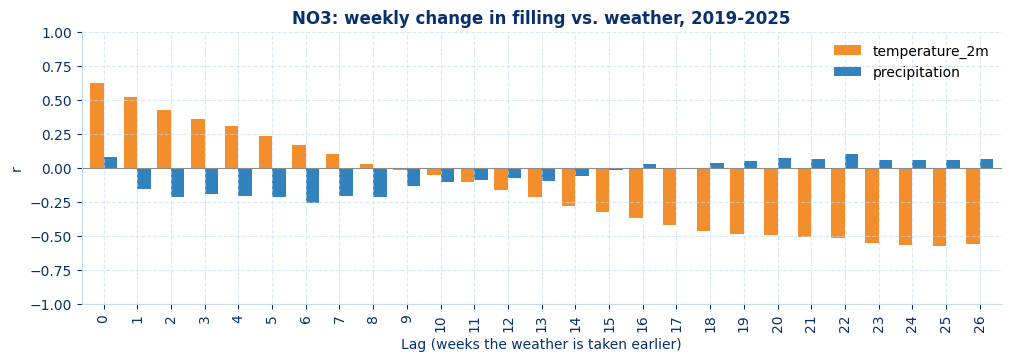

In [20]:
# Correlation with the weekly change in filling for every lag (0-26 weeks).
# The series are joined first, so the lag always means whole weeks.
both_all = pd.concat([change_no3, weekly_no3], axis=1, join="inner").dropna()
lags = pd.DataFrame({
    var: correlation_by_lag(both_all["change"], both_all[var], max_lag=26)
    for var in ["temperature_2m", "precipitation"]
})
print(lags.round(2).T)

fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
lags.plot.bar(ax=ax, color=[COLORS["accent"], COLORS["primary"]], width=0.8)
ax.axhline(0, color=COLORS["neutral"], lw=0.8)
ax.set(xlabel="Lag (weeks the weather is taken earlier)", ylabel="r",
       ylim=(-1, 1),
       title="NO3: weekly change in filling vs. weather, 2019-2025")
plt.show()

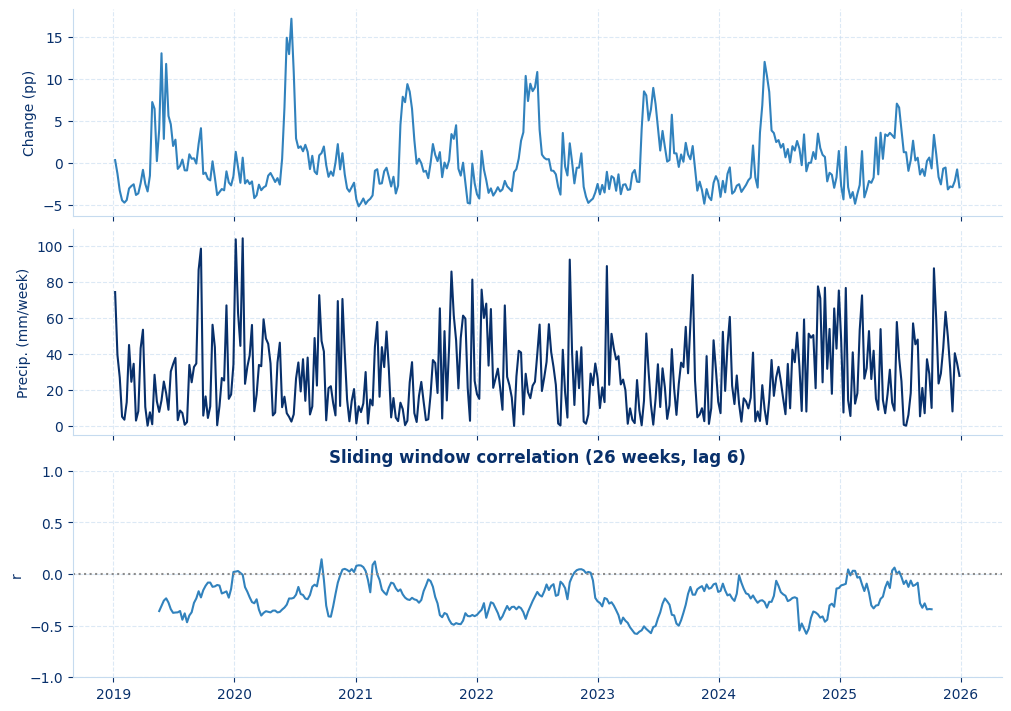

In [21]:
# Sliding window correlation: precipitation vs. weekly change in filling,
# with the lag that gave the strongest relationship above
best_lag = int(lags["precipitation"].abs().idxmax())
both = both_all[["change", "precipitation"]]
swc = sliding_window_correlation(both["change"], both["precipitation"],
                                 window=26, lag=best_lag)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout="constrained")
axes[0].plot(both.index, both["change"], color=COLORS["primary"])
axes[0].set_ylabel("Change (pp)")
axes[1].plot(both.index, both["precipitation"], color=COLORS["dark"])
axes[1].set_ylabel("Precip. (mm/week)")
axes[2].plot(swc.index, swc, color=COLORS["primary"])
axes[2].axhline(0, color=COLORS["neutral"], ls=":")
axes[2].set(ylabel="r", ylim=(-1, 1),
            title=f"Sliding window correlation (26 weeks, lag {best_lag})")
plt.show()

### Findings from the app

The controls were explored for NO3 (Central) and VASS2 (West), 2020–2025,
with a 26-week window. Values are Pearson's r.

**Temperature** has the clearest relationship with the weekly change in
filling: r = 0.63 (NO3) and 0.69 (VASS2) at lag 0, falling quickly with
longer lags. The sliding window shows that it depends on the season: it
is strongest in March–May (r ≈ 0.8–0.9, warm weeks start the snowmelt)
and in winter (≈ 0.7, mild weeks mean rain instead of snow and less
drawdown), and weakest in July–August (≈ 0.1–0.4, when the snow is gone).
At lags around 24–26 weeks the correlation is about −0.6, but this only
mirrors the yearly cycle (half a year later the season is reversed) and
is not a useful predictor.

**Precipitation** matters much more in the west: at lag 0, r = 0.31 for
VASS2 but only 0.07 for NO3. In autumn and winter both areas show a
clear positive window correlation (r ≈ 0.5–0.7 from October to
February), while it is close to zero in spring, when the inflow is
driven by snowmelt rather than by rain that week. The strength also
varies from year to year (VASS2: from 0.16 in 2020 to 0.59 in 2025).
Lags of 2–9 weeks give weak negative values (≈ −0.2 to −0.3), probably
because precipitation in winter is stored as snow.

**Wind speed** and **relative humidity** are weaker. Humidity behaves
like a proxy for wet, mild weather (r = 0.29 at lag 0 in NO3, ≈ 0.6 in
winter), and wind changes sign with the season (positive in winter,
about −0.35 in spring), so neither adds much beyond temperature and
precipitation.

**Level vs. change:** using the filling *level* instead gives misleading
results. For VASS2 and temperature the overall correlation peaks at a
lag of 11–12 weeks (r = 0.69), and the window correlation swings from
−0.68 to 0.89 through the year, because both series follow the seasons.

**Consequences for forecasting:** model the weekly change (differencing)
rather than the level, use temperature and precipitation with short lags
(0–1 weeks) as exogenous variables, and include the season, since the
effect of the weather is very different in spring and summer. The
relationship also varies between years, so a model that keeps learning
(as in River) is a good fit.